# Key-point - search-analysis

In the expirment `030_feature-matching_pattern-matching-first.ipynb` a problem with the keypoint-matching was found (and solved in `040_feature-matching_filter-matches-to-same-points.ipynb`)

To understand this problem better, and to possibly find a more robust solution to the problem, some further analysis is done in this experiment.

In [24]:
from collections.abc import Callable, Sequence
from dataclasses import dataclass

import cv2
import matplotlib.pyplot as plt
import numpy as np

Load the two meter-dial-Reference-Images:

- jpg with blurred border and black areas
- png with hard borders and alpha-channel

The train_image is also loaded for comparision.

In [25]:
query_img_jpg : np.ndarray
query_img_png : np.ndarray
train_image : np.ndarray

METER_DIAL_IMAGE_JPG_PATH = "data/2026-10-32_Fotos_water-meter/2026-11-08_water-meter-dial_reference-image_v2.jpg"
METER_DIAL_IMAGE_PNG_PATH = "data/2026-10-32_Fotos_water-meter/2026-11-08_water-meter-dial_reference-image_v3.png"
CURRENT_IMAGE_PATH = "data/degeneraterd-homography/current.png"

rv = cv2.imread(METER_DIAL_IMAGE_JPG_PATH, cv2.IMREAD_UNCHANGED)
assert isinstance(rv, np.ndarray), "Preselect image not found."
query_img_jpg = rv

rv = cv2.imread(METER_DIAL_IMAGE_PNG_PATH, cv2.IMREAD_UNCHANGED)
assert isinstance(rv, np.ndarray), "Meter dial image not found."
query_img_png = rv

rv = cv2.imread(CURRENT_IMAGE_PATH, cv2.IMREAD_UNCHANGED)
assert isinstance(rv, np.ndarray), "Current image not found."
train_image = rv


Now we find the keypoints in the images.

When finding keypoints for the png-Image, the alpha-channel is also used as mask. So only keypoints are found in the non-transparent-area (The alpha-value is either 0 or 255, there are no intermediate values).

One of the **questions** to be answered is: Does the hard border of the meter-dial-area in the png-image produce keypoints? Those keypoints would not be any real features!

In [26]:

sift = cv2.SIFT.create()

png_mask = query_img_png[:, :, 3]

keypoints_query_png: Sequence[cv2.KeyPoint]
descriptors_query_png: np.ndarray
keypoints_query_png, descriptors_query_png = sift.detectAndCompute(query_img_png, png_mask)

keypoints_query_jpg: Sequence[cv2.KeyPoint]
descriptors_query_jpg: np.ndarray
keypoints_query_jpg, descriptors_query_jpg = sift.detectAndCompute(query_img_jpg, None)

keypoints_train: Sequence[cv2.KeyPoint]
descriptors_train: np.ndarray
keypoints_train, descriptors_train = sift.detectAndCompute(train_image, None)

Draw the keypoints as small circles in the images and show them:

In [27]:
def draw_keypoints(image: np.ndarray, keypoints: Sequence[cv2.KeyPoint]) -> None:
    image_copy = image.copy()
    for kp in keypoints:
        x, y = int(kp.pt[0]), int(kp.pt[1])
        cv2.circle(image_copy, (x, y), 3, (0, 255, 0), -1)

    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(image_copy, cv2.COLOR_BGR2RGB))

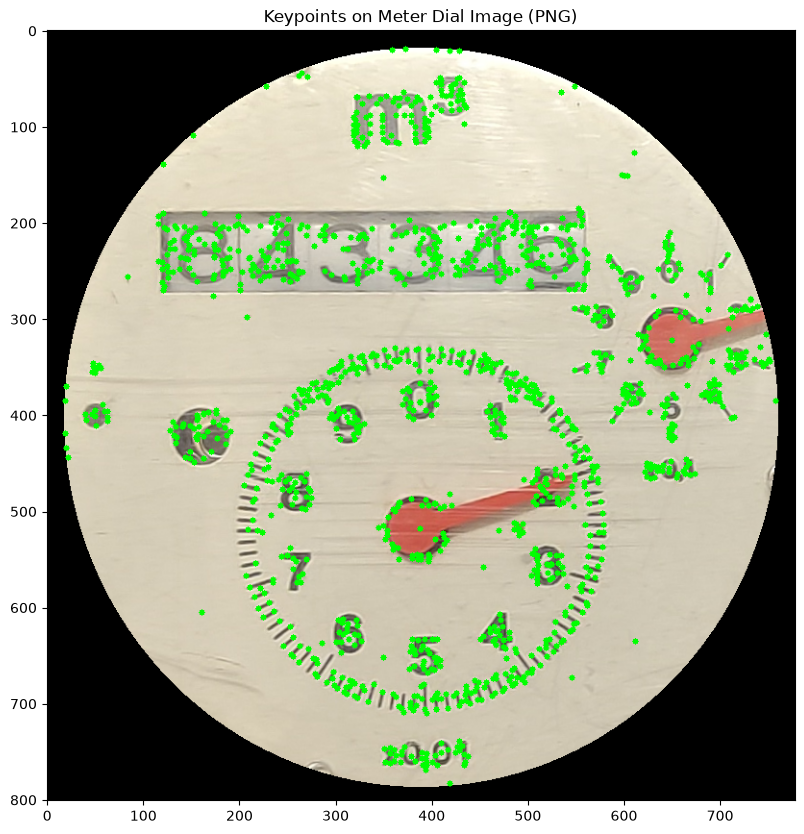

In [28]:
draw_keypoints(query_img_png, keypoints_query_png)
plt.title("Keypoints on Meter Dial Image (PNG)")
plt.show()

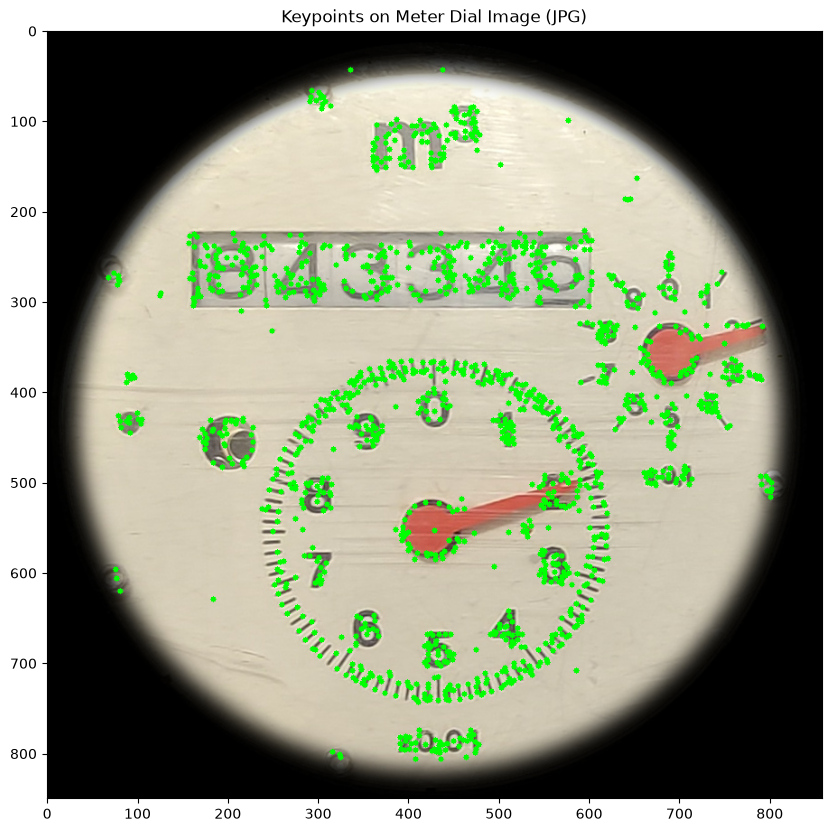

In [29]:
draw_keypoints(query_img_jpg, keypoints_query_jpg)
plt.title("Keypoints on Meter Dial Image (JPG)")
plt.show()

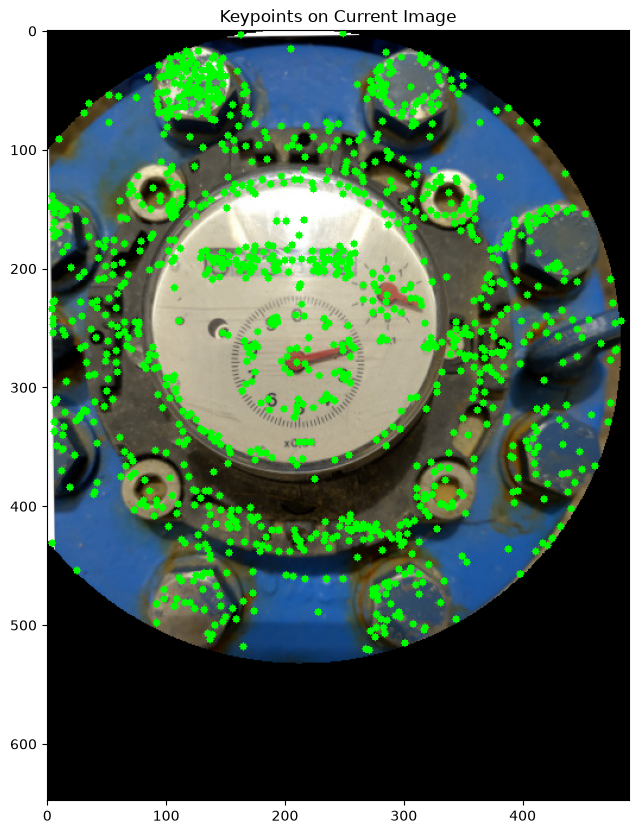

In [30]:
draw_keypoints(train_image, keypoints_train)
plt.title("Keypoints on Current Image")
plt.show()

### First conclusions: 

1. A small amount of keypoints is found on the hard border of the png-Image, but they should not be much of a problem, or they can even be avoided.

   - The benefit of having the alpha-channel as mask in png-Images is more important than some false keypoints
   - The false keypoints could even be mitigated, if blurring the border is also used in the png-image and not just in the jpg-image

1. The ligthning-conditions do really matter: In the current-image no keypoints are found for the 'm³'-mark because it is not visible because of reflections.

# Good Matching- and filter- algorithm

[Opencv-Tutorial on feature-matching](https://docs.opencv.org/4.13.0/dc/dc3/tutorial_py_matcher.html)

Brute-Force-matching should definitively be the best approach (compare each keypoint in one image with the keypoint in the other image). But there is more tweaking possible: 

`crossCheck=True`:

> If it is true, Matcher returns only those matches with value (i,j) such that i-th descriptor in set A has j-th descriptor in set B as the best match and vice-versa.That is, the two features in both sets should match each other. It provides consistent result, and is a good alternative to ratio test proposed by D.Lowe in SIFT paper.

Different Match-methods:

> two important methods are BFMatcher.match() and BFMatcher.knnMatch(). First one returns the best match. Second method returns k best matches where k is specified by the user. It may be useful when we need to do additional work on that.

My assumption: `knnMatch` with k=1 is the same as `match`

## Common functions

The following functions will be used to do the Match-finding and calculation of homography.

In [31]:
DEFAULT_LOWE_MATCH_RATIO = 0.75
DEFAULT_MIN_MATCHES = 10
DEFUALT_RANSAC_REPROJ_THRESHOLD = 5.0
DEFAULT_RANSAC_METHOD = cv2.RANSAC

@dataclass
class HomographyResult:
    homography: np.ndarray
    used_query_points: np.ndarray
    used_train_points: np.ndarray
    good_matches: Sequence[cv2.DMatch]
    filtered_matches: Sequence[cv2.DMatch]

There are two strategies do match keypoints found in the query- and the train-image:

- Lowe's ratio-test
- Cross-check = True

In [32]:
def match_keypoints_lowe( 
        desc_query: np.ndarray, 
        desc_train: np.ndarray,
        lowe_match_ratio: float = DEFAULT_LOWE_MATCH_RATIO
        ) -> Sequence[cv2.DMatch]:
    # Create a BFMatcher object with L2 norm and no cross-checking
    norm = cv2.NORM_L2 if desc_query.dtype == np.float32 else cv2.NORM_HAMMING
    bf = cv2.BFMatcher(norm, crossCheck=False)
    raw : Sequence[Sequence[cv2.DMatch]] = bf.knnMatch(
                queryDescriptors=desc_query, 
                trainDescriptors=desc_train, 
                k=2
                )
    good_matches = []
    for m, n in raw:
        if m.distance < lowe_match_ratio * n.distance:
            good_matches.append(m)
    return good_matches


def match_keypoints_crosscheck(
        desc_query: np.ndarray, 
        desc_train: np.ndarray
        ) -> Sequence[cv2.DMatch]:
    # Create a BFMatcher object with L2 norm and cross-checking enabled
    norm = cv2.NORM_L2 if desc_query.dtype == np.float32 else cv2.NORM_HAMMING
    bf = cv2.BFMatcher(norm, crossCheck=True)
    good_matches = bf.match(desc_query, desc_train)
    return good_matches

Finally, with the following function the homography will be computed. It must be passed:

- The descriptors and keypoints found by `sift.detect_and_compute` for the query-image, and
- for the train-image
- The `matches_function` to use: either `match_keypoints_lowe` or `match_keypoints_crosscheck`
- `filter_matches_function`: An optional function for preprocessing the good_matches and returning only a subset of the passed goot matches

In [33]:
def compute_homography( 
        img_query: np.ndarray,
        img_train: np.ndarray,
        detector: cv2.Feature2D,
        matches_function: Callable[[np.ndarray, np.ndarray], Sequence[cv2.DMatch]],
        filter_matches_function: Callable[[Sequence[cv2.DMatch], 
                                           np.ndarray,
                                           np.ndarray,
                                           np.ndarray,
                                           Sequence[cv2.KeyPoint],
                                           np.ndarray,
                                           Sequence[cv2.KeyPoint]], 
                                           Sequence[cv2.DMatch]] | None = None,
        min_matches: int = DEFAULT_MIN_MATCHES,
        ransac_method: int = DEFAULT_RANSAC_METHOD,
        ransac_reproj_threshold: float = DEFUALT_RANSAC_REPROJ_THRESHOLD
        ) -> HomographyResult:

    # SIFT
    desc_query: np.ndarray
    keypoints_query: Sequence[cv2.KeyPoint]
    desc_train: np.ndarray
    keypoints_train: Sequence[cv2.KeyPoint]
    
    png_mask = img_query[:, :, 3] if img_query.shape[2] == 4 else None
    keypoints_query, desc_query = detector.detectAndCompute(img_query, png_mask)
    keypoints_train, desc_train = detector.detectAndCompute(img_train, None)
    
    # Create a BFMatcher object with L2 norm and no cross-checking
    good_matches = matches_function(desc_query, desc_train)
    
    if filter_matches_function is not None:
        filtered_matches = filter_matches_function(good_matches,
                                                   img_query,
                                                   img_train,
                                                   desc_query,
                                                   keypoints_query,
                                                   desc_train,
                                                   keypoints_train)
    else:
        filtered_matches = good_matches

    if len(filtered_matches) < max(4, min_matches):
        raise ValueError(f"Not enough distinct good matches found. Found {len(filtered_matches)}, expected at least {max(4, min_matches)}.")

    query_pts = np.zeros((len(filtered_matches), 1, 2), dtype=np.float32)
    train_pts = np.zeros((len(filtered_matches), 1, 2), dtype=np.float32)
    for i, match in enumerate(filtered_matches):
        query_pts[i, 0] = keypoints_query[match.queryIdx].pt
        train_pts[i, 0] = keypoints_train[match.trainIdx].pt
    H, inliers = cv2.findHomography(query_pts, train_pts, ransac_method, ransac_reproj_threshold)
    if H is None or H.shape != (3, 3):
        raise ValueError("Homography could not be computed.")
    if inliers is None or np.count_nonzero(inliers) < max(4, min_matches):
        raise ValueError("Not enough inliers after RANSAC.")
    inlier_mask = inliers.ravel().astype(bool)

    used_query_pts = query_pts[inlier_mask].reshape(-1, 2)
    used_train_pts = train_pts[inlier_mask].reshape(-1, 2)

    return HomographyResult(
        homography=H,
        used_query_points=used_query_pts,
        used_train_points=used_train_pts,
        good_matches=good_matches,
        filtered_matches=filtered_matches
    )


Helper function to draw matches:

In [34]:
def draw_matches(query_image: np.ndarray, 
                 train_image: np.ndarray, 
                 points_reference: np.ndarray, 
                 points_current: np.ndarray
                 ) -> None:
    
    line_width: int = 3 if len(points_reference) <= 15 else 2

    SPACE = 20
    height = max(query_image.shape[0], train_image.shape[0])
    width = query_image.shape[1] + SPACE + train_image.shape[1]
    canvas = np.full((height, width, 3), 255, dtype=np.uint8)
    canvas[:query_image.shape[0], :query_image.shape[1]] = query_image[:,:,:3]
    x_offset = query_image.shape[1] + SPACE
    canvas[:train_image.shape[0], x_offset:] = train_image[:,:,:3]

    rng = np.random.default_rng()
    for i in range(len(points_reference)):
        color = tuple(int(c) for c in rng.integers(0, 256, size=3))

        x1, y1 = points_reference[i]
        pt_ref = (round(x1), round(y1))

        x2, y2 = points_current[i]
        pt_cur = (round(x2) + x_offset, round(y2))
        cv2.line(canvas, pt_ref, pt_cur, color, line_width)
        cv2.circle(canvas, pt_ref, 10, color, line_width)
        cv2.circle(canvas, pt_cur, 10, color, line_width)

    plt.figure(figsize=(16, 8))
    plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

## Degenerated homograpyh

This matching didn't work with the png-image:

- Lowe's Ration Test
- used reference-image: png 
- no preprocessing of good matches

In [35]:
MATCHES_TO_DRAW = 30

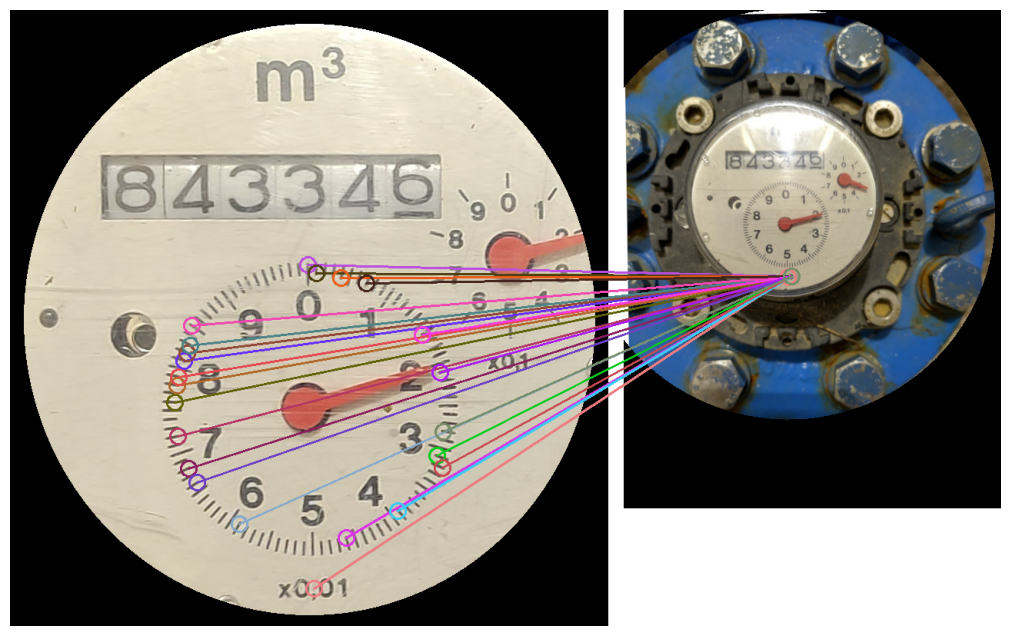

In [36]:
homography_result = compute_homography(
    img_query=query_img_png,
    img_train=train_image,
    detector=cv2.SIFT.create(),
    matches_function=match_keypoints_lowe,
    filter_matches_function=None,
    ransac_method=cv2.RANSAC,
    ransac_reproj_threshold=5.0
)

draw_matches(
    query_image=query_img_png,
    train_image=train_image,
    points_reference=homography_result.used_query_points[:MATCHES_TO_DRAW],
    points_current=homography_result.used_train_points[:MATCHES_TO_DRAW]
)

## Lowe's Ratio matching with jpg

Interestingly, with the jpg-image the homography-computation does not degenerate.

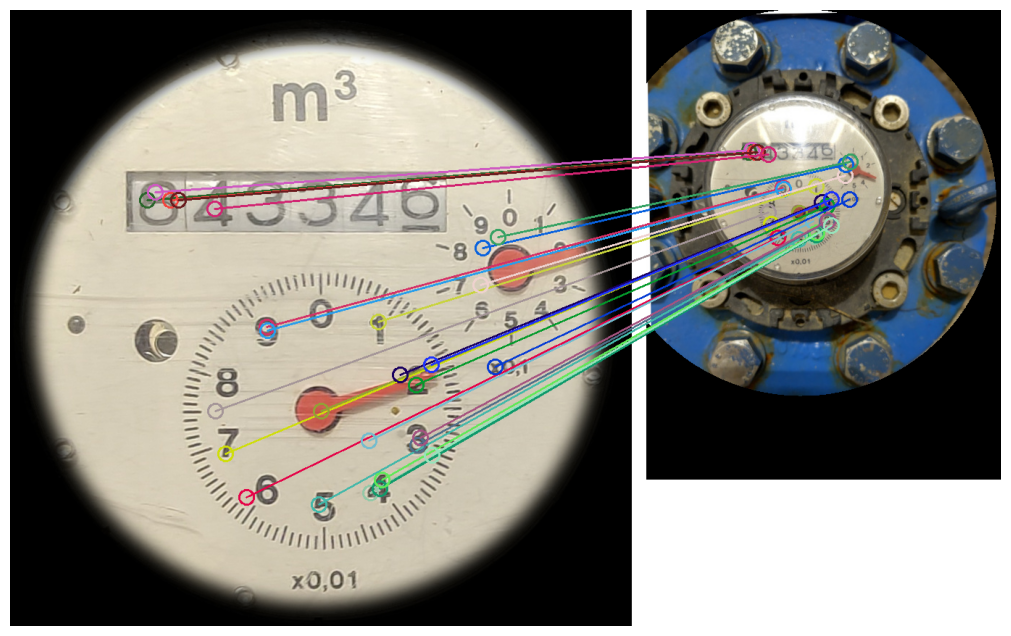

In [37]:
homography_result = compute_homography(
    img_query=query_img_jpg,
    img_train=train_image,
    detector=cv2.SIFT.create(),
    matches_function=match_keypoints_lowe,
    filter_matches_function=None,
    ransac_method=cv2.RANSAC,
    ransac_reproj_threshold=5.0
)

draw_matches(
    query_image=query_img_jpg,
    train_image=train_image,
    points_reference=homography_result.used_query_points[:MATCHES_TO_DRAW],
    points_current=homography_result.used_train_points[:MATCHES_TO_DRAW]
)


## Brute-Force with `crossCheck=True`

Instead of Lowe's ratio-test a simple Match with `crossCheck=True` is performed:

### With png-image as the query-image

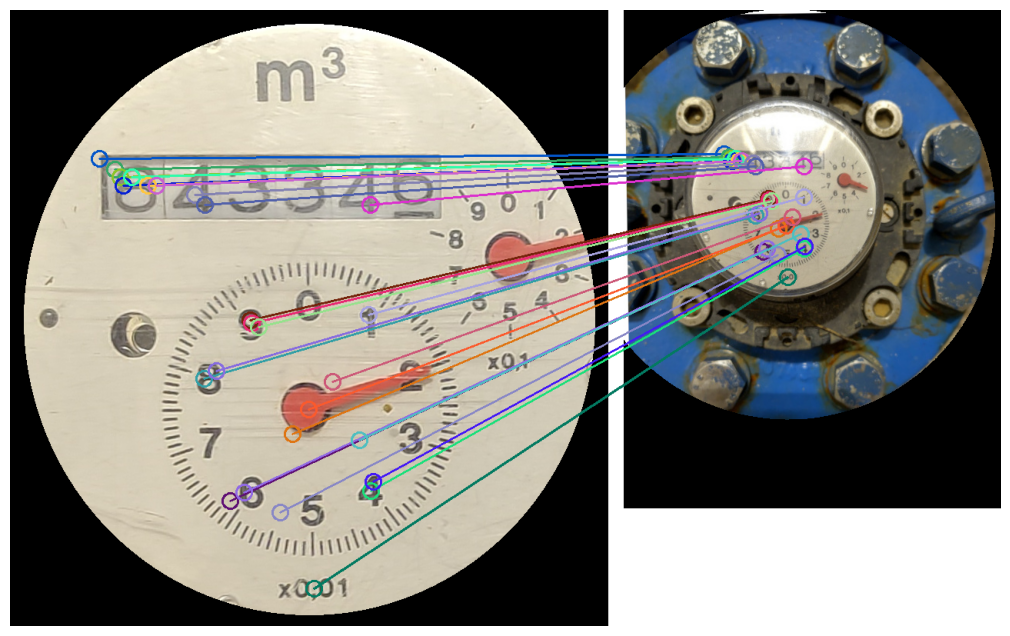

In [38]:
homography_result = compute_homography(
    img_query=query_img_png,
    img_train=train_image,
    detector=cv2.SIFT.create(),
    matches_function=match_keypoints_crosscheck,
    filter_matches_function=None,
    ransac_method=cv2.RANSAC,
    ransac_reproj_threshold=5.0
)

draw_matches(
    query_image=query_img_png,
    train_image=train_image,
    points_reference=homography_result.used_query_points[:MATCHES_TO_DRAW],
    points_current=homography_result.used_train_points[:MATCHES_TO_DRAW]
)

### with jpg-image as query-image

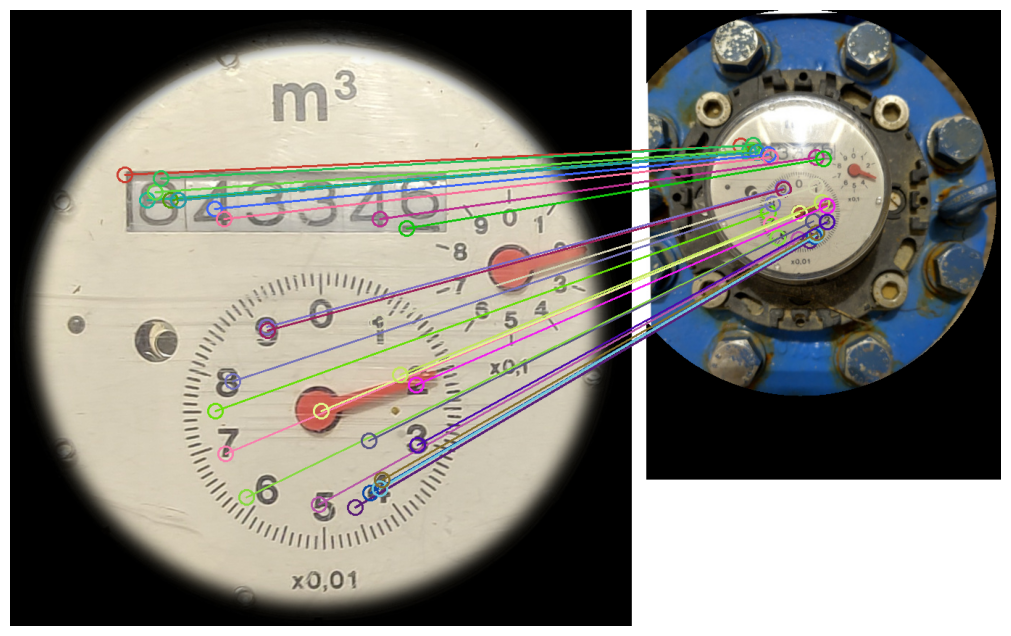

In [39]:
homography_result = compute_homography(
    img_query=query_img_jpg,
    img_train=train_image,
    detector=cv2.SIFT.create(),
    matches_function=match_keypoints_crosscheck,
    filter_matches_function=None,
    ransac_method=cv2.RANSAC,
    ransac_reproj_threshold=5.0
)

draw_matches(
    query_image=query_img_jpg,
    train_image=train_image,
    points_reference=homography_result.used_query_points[:MATCHES_TO_DRAW],
    points_current=homography_result.used_train_points[:MATCHES_TO_DRAW]
)


## Conclusions of this section

It is not really clear, why the homography-calculation fails in one case, and the other cases not. "Copilot" also just repeats my assumptions about the border, but. I don't think that "Copilot's" answer is correct.




# Strategies to prevent degeneration of computed homography

In this section only the png-query-image and Lowe's-ratio-Test is used, as this led to the degenerated homography. Different strategies are tested to prevent the degeneration of the homography-calculation.

## Avoid duplicate keypoints

Copilot found a solution, which is used in `040_feature-matching_filter-matches-to-same-points.ipynb`: First sort good_matches by distance (lower discacne first). Then use only matches with keypoints that have not already been used.

This approach is quite simple, and it works in this case. It should be safe to use this filter-algorithm. 

But maybe it is to naive?

In [40]:
def avoid_duplicate_keypoints(
        good_matches: Sequence[cv2.DMatch],
        img_query: np.ndarray,
        img_train: np.ndarray,
        desc_query: np.ndarray,
        keypoints_query: Sequence[cv2.KeyPoint],
        desc_train: np.ndarray,
        keypoints_train: Sequence[cv2.KeyPoint]) -> Sequence[cv2.DMatch]:
    """
    Filter out matches that have duplicate keypoints in either the query or train image.
    """
    # only used function argument is good_matches:
    del img_query, img_train, desc_query, keypoints_query, desc_train, keypoints_train

    seen_query_indices = set()
    seen_train_indices = set()
    filtered_matches = []

    sorted_matches = sorted(good_matches, key=lambda m: m.distance)

    for match in sorted_matches:
        if (match.queryIdx not in seen_query_indices and
                match.trainIdx not in seen_train_indices):
            filtered_matches.append(match)
            seen_query_indices.add(match.queryIdx)
            seen_train_indices.add(match.trainIdx)

    return filtered_matches 

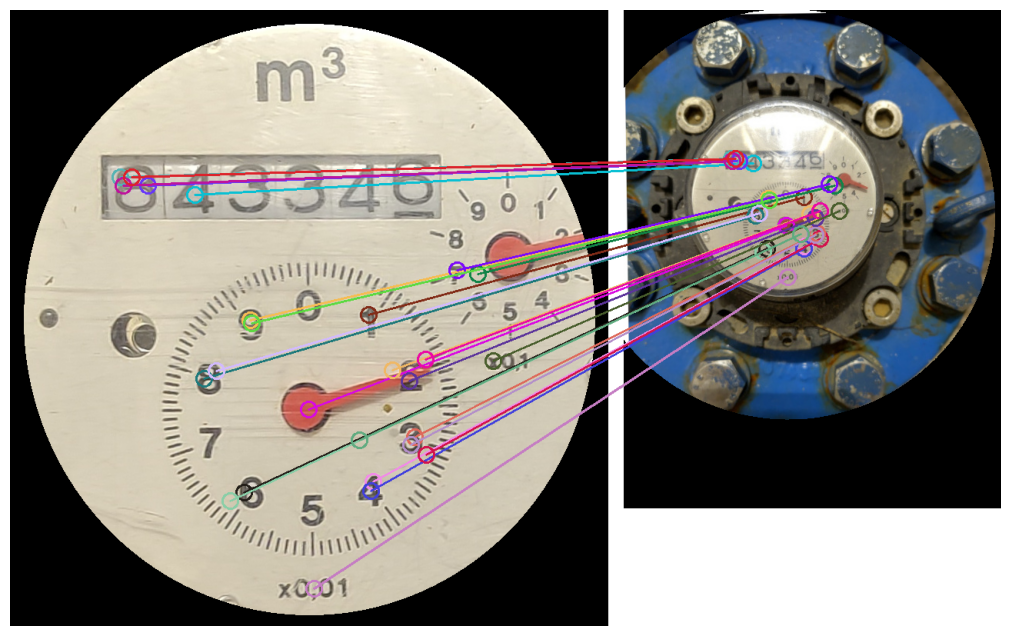

In [41]:
homography_result = compute_homography(
    img_query=query_img_png,
    img_train=train_image,
    detector=cv2.SIFT.create(),
    matches_function=match_keypoints_lowe,
    filter_matches_function=avoid_duplicate_keypoints,
    ransac_method=cv2.RANSAC,
    ransac_reproj_threshold=5.0
)

draw_matches(
    query_image=query_img_png,
    train_image=train_image,
    points_reference=homography_result.used_query_points[:MATCHES_TO_DRAW],
    points_current=homography_result.used_train_points[:MATCHES_TO_DRAW]
)

## MAGSAC++ instead of RANCAC

Mistral's Vibe AI also sugested other things to try:

First use an imporved version of RANSAC, namely MAGSAC++.

This does not lead to an improvement: The algorithm finds two additional matches, but both are wrong!

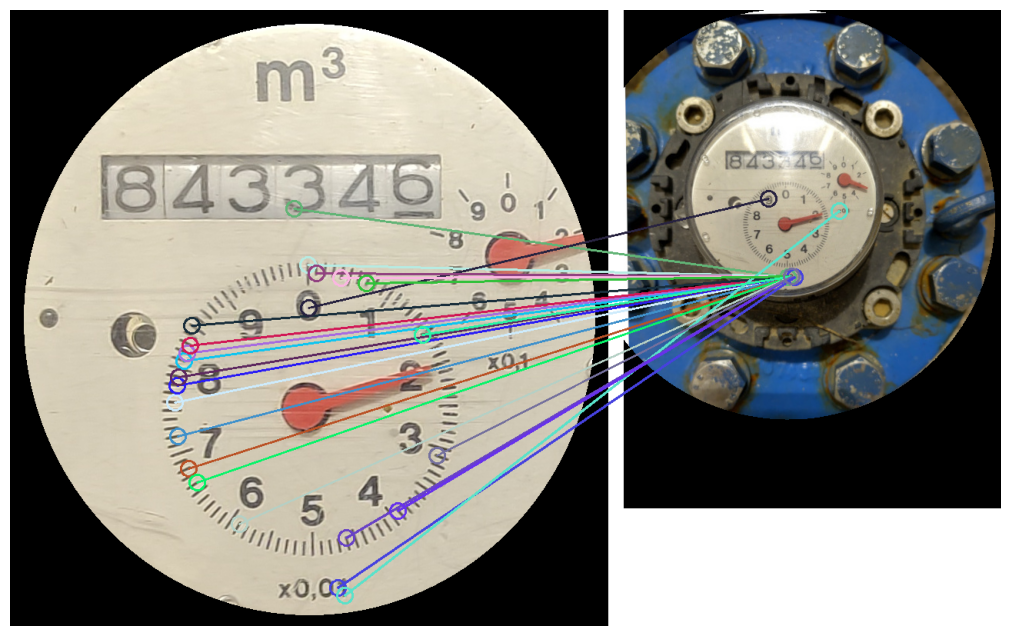

In [42]:
homography_result = compute_homography(
    img_query=query_img_png,
    img_train=train_image,
    detector=cv2.SIFT.create(),
    matches_function=match_keypoints_lowe,
    filter_matches_function=None,
    ransac_method=cv2.USAC_MAGSAC,
    ransac_reproj_threshold=5.0
)

draw_matches(
    query_image=query_img_png,
    train_image=train_image,
    points_reference=homography_result.used_query_points[:MATCHES_TO_DRAW],
    points_current=homography_result.used_train_points[:MATCHES_TO_DRAW]
)

## Grid based motion statistics (GMS)

A grid is put on both images. GMS keeps track, of which keypoint lies in which grid-cell and then filters out unplausible matches.

This needs the python-package opencv-contrib.

In [43]:
def use_gms(
        good_matches: Sequence[cv2.DMatch],
        img_query: np.ndarray,
        img_train: np.ndarray,
        desc_query: np.ndarray,
        keypoints_query: Sequence[cv2.KeyPoint],
        desc_train: np.ndarray,
        keypoints_train: Sequence[cv2.KeyPoint]) -> Sequence[cv2.DMatch]:
    """
    Filter matches using the GMS (Grid-based Motion Statistics) algorithm.
    """

    width_query, height_query = img_query.shape[1], img_query.shape[0]
    width_train, height_train = img_train.shape[1], img_train.shape[0]

    return cv2.xfeatures2d.matchGMS( (width_query, height_query), 
                                     (width_train, height_train),
                                     keypoints_query,
                                     keypoints_train, 
                                     good_matches, 
                                     withRotation=True, 
                                     withScale=True)

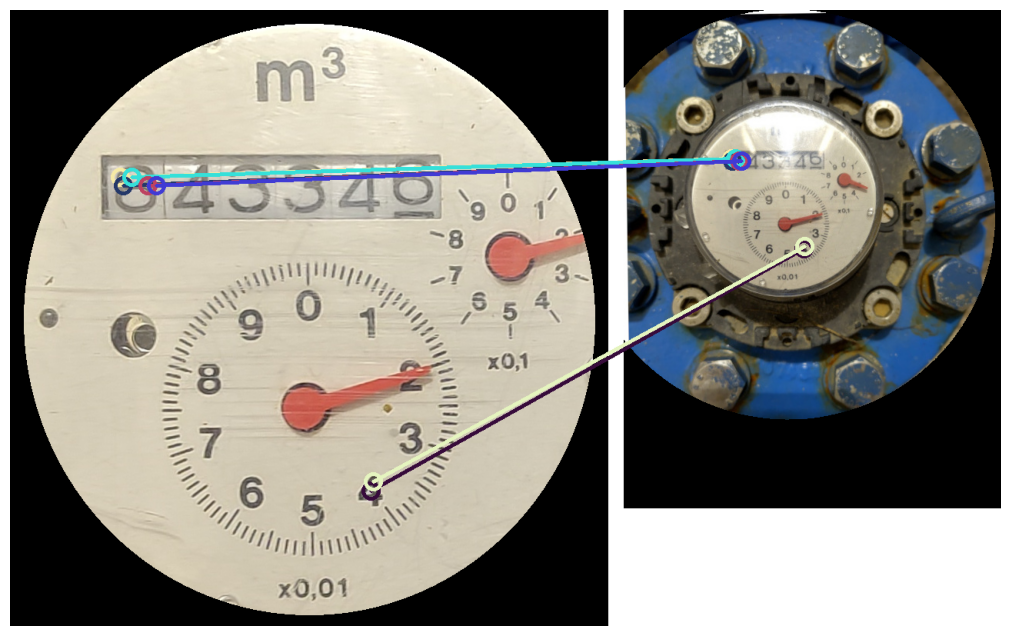

In [44]:
homography_result = compute_homography(
    img_query=query_img_png,
    img_train=train_image,
    detector=cv2.SIFT.create(),
    matches_function=match_keypoints_lowe,
    filter_matches_function=use_gms,
    ransac_method=cv2.RANSAC,
    ransac_reproj_threshold=5.0
)

draw_matches(
    query_image=query_img_png,
    train_image=train_image,
    points_reference=homography_result.used_query_points[:MATCHES_TO_DRAW],
    points_current=homography_result.used_train_points[:MATCHES_TO_DRAW]
)

Conclusion: The matched Keypoints are correct. But too many keypoints are filtered out: With the remaining keypoints it is impossible to compute a correct homography.

## Scale- and orientation-consitency

SIFT computes `size` (scale) and `angle` (orientation) of each keypoint. So:

- The `size`-ratio of the matches keypoints must be similar. (Scale-Factor between the images)
- The `angles`-difference of matched keypoints must be similar. (Rotation between the images)

In [106]:
def size_and_scale_consitency(
            good_matches: Sequence[cv2.DMatch],
            img_query: np.ndarray,
            img_train: np.ndarray,
            desc_query: np.ndarray,
            keypoints_query: Sequence[cv2.KeyPoint],
            desc_train: np.ndarray,
            keypoints_train: Sequence[cv2.KeyPoint]) -> Sequence[cv2.DMatch]:
    """Filter out matches that are inconsistent in terms of keypoint size and scale."""

    size_ratios = np.array([ keypoints_query[m.queryIdx].size / keypoints_train[m.trainIdx].size for m in good_matches])
    angle_diffs = np.array([ (keypoints_query[m.queryIdx].angle - keypoints_train[m.trainIdx].angle) % 360 for m in good_matches])
    size_ratio_med = np.median(size_ratios)
    angle_diff_med = np.median(angle_diffs)

    filtered_matches = []
    for i, match in enumerate(good_matches):
        size_ratio = size_ratios[i]
        angle_diff = angle_diffs[i]

        if (abs(size_ratio - size_ratio_med) < 0.8 * size_ratio_med and
                abs(angle_diff - angle_diff_med) <= 90.0
                ):
            filtered_matches.append(match)

    return filtered_matches

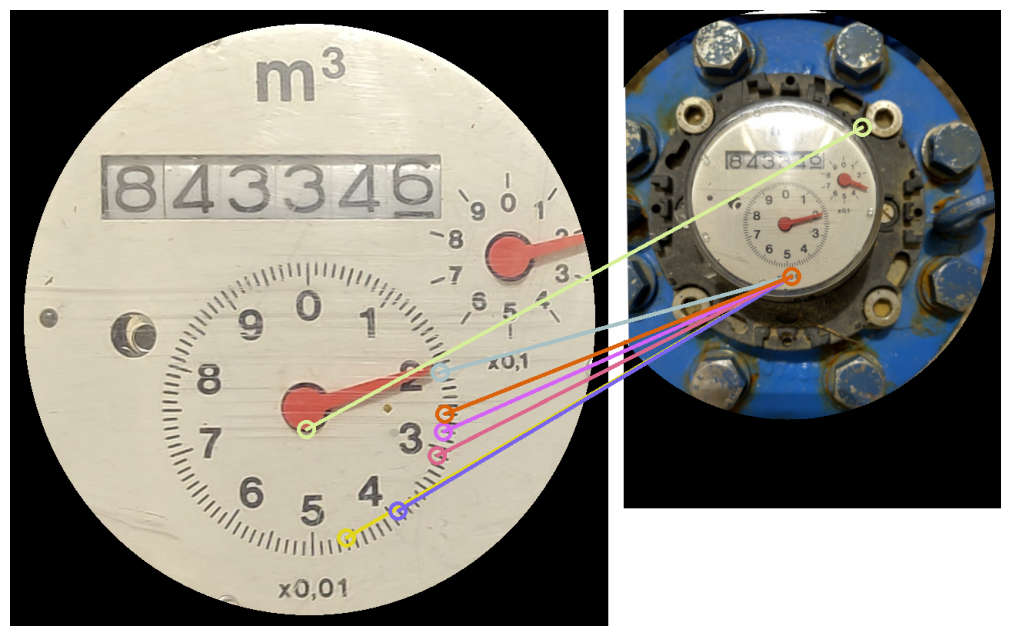

In [107]:
homography_result = compute_homography(
    img_query=query_img_png,
    img_train=train_image,
    detector=cv2.SIFT.create(),
    matches_function=match_keypoints_lowe,
    filter_matches_function=size_and_scale_consitency,
    ransac_method=cv2.RANSAC,
    ransac_reproj_threshold=5.0
)

draw_matches(
    query_image=query_img_png,
    train_image=train_image,
    points_reference=homography_result.used_query_points[:MATCHES_TO_DRAW],
    points_current=homography_result.used_train_points[:MATCHES_TO_DRAW]
)

Many of the matches are filterd out. All remaining matches are wrong.

The limits in the filtering-algorithm are even very high. If the limits were set to reasonable values, then not enough values would remain to compute a homography:

- `abs(size_ratio - size_ratio_med) < 0.5 * size_ratio_med`
- `abs(angle_diff - angle_diff_med) <= 45.0`



### Conclusion

Only the naive "avoiding of duplicate keypoint useage" leads to a good result. All other strategies do not!

This naive approach has already been implemented in the previous experiment `040_feature-matching_filter-matches-to-same-points.ipynb`